In [1]:
using WAVI, Plots, NCDatasets

In [2]:
function mismip_plus_bed(x,y)
    xbar = 300000.0
    b0 = -150.0; b2 = -728.8; b4 = 343.91; b6 = -50.75;
    wc = 24000.0; fc = 4000.0; dc = 500.0;
    bx(x)=b0+b2*(x/xbar)^2+b4*(x/xbar)^4+b6*(x/xbar)^6;
    by(y)= dc*( (1+exp(-2(y-wc)/fc))^(-1) + (1+exp(2(y+wc)/fc))^(-1) );
    b = max(bx(x) + by(y), -720.0);
    return b;
end

mismip_plus_bed (generic function with 1 method)

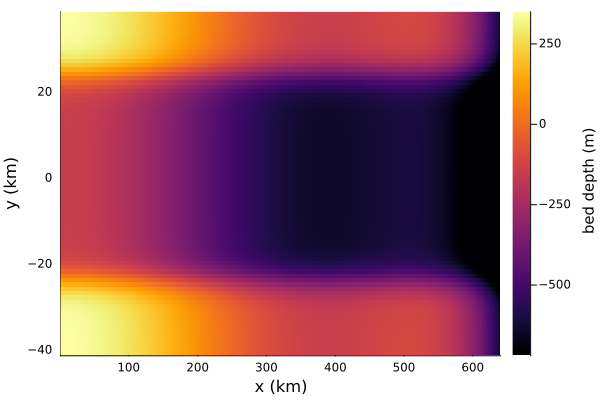

In [3]:
dx = 1.e3;
dy = 1.e3;
nx = round(Int, 640*1e3/dx);
ny = round(Int, 80*1e3/dx);
xx=[i*dx for i=1:nx, j=1:ny];
yy=[j*dy for i=1:nx, j=1:ny] .- 42000;
x = xx[:,1];
y = yy[1,:];

# Now we can plot
plt =  Plots.heatmap(x/1e3, y/1e3, mismip_plus_bed.(xx,yy)', 
                    xlabel = "x (km)", 
                    ylabel = "y (km)",
                    colorbar_title = "\n bed depth (m)",
                    right_margin = 4Plots.mm)
plot!(size = (600,400))

In [4]:
dx = 8.e3;
dy = 8.e3;
nx = round(Int, 640*1e3/dx);
ny = round(Int, 80*1e3/dx); #fix the number of grid-cells in the x and y directions to match set extents

u_iszero = falses(nx+1,ny); #build x-direction velocity boundary condition matrix with no zero boundary conditions anywhere 
u_iszero[1,:].=true;        #set the x-direction velocity to zero at x = 0.
v_iszero=falses(nx,ny+1);   #build x-direction velocity boundary condition matrix with no zero boundary conditions anywhere 
v_iszero[:,1].=true;        #set the y-direction velocity to zero at y = 0 (free slip)
v_iszero[:,end].=true;       #set the y-direction velocity to zero at y = 84km (free slip)
v_iszero[1,:].=true;         #set the y-direction velocity to zero at x = 0km (no slip in combination with u_iszero)

grid = Grid(nx = nx, 
            ny = ny,   
            dx = dx, 
            dy = dy,
            u_iszero = u_iszero, 
            v_iszero = v_iszero)

Grid{Float64, Int64}(80, 10, 4, 8000.0, 8000.0, 0.0, -40000.0, Bool[1 1 … 1 1; 1 1 … 1 1; … ; 1 1 … 1 1; 1 1 … 1 1], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[1 1 … 1 1; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[1 1 … 1 1; 1 0 … 0 1; … ; 1 0 … 0 1; 1 0 … 0 1], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], [4000.0 4000.0 … 4000.0 4000.0; 12000.0 12000.0 … 12000.0 12000.0; … ; 628000.0 628000.0 … 628000.0 628000.0; 636000.0 636000.0 … 636000.0 636000.0], [-36000.0 -28000.0 … 28000.0 36000.0; -36000.0 -28000.0 … 28000.0 36000.0; … ; -36000.0 -28000.0 … 28000.0 36000.0; -36000.0 -28000.0 … 28000.0 36000.0], [0.0 0.0 … 0.0 0.0; 8000.0 8000.0 … 8000.0 8000.0; … ; 632000.0 632000.0 … 632000.0 632000.0; 640000.0 640000.0 … 640000.0 640000.0], [-36000.0 -28000.0 … 28000.0 36000.0; -36000.0 -28000.0 … 28000.0 36000.0; … ; -36000.0 -28000.0 … 28000.0 36000.0; -36000.0 -28000.0 … 28000.0 36000.0], [4000.0 4000.0 … 4000

In [5]:
solver_params = SolverParams(maxiter_picard = 1)

initial_conditions = InitialConditions(initial_thickness = 100 .* ones(nx,ny));
params = Params( accumulation_rate = 0.3);

model = Model(grid = grid,
            bed_elevation = mismip_plus_bed, 
            initial_conditions = initial_conditions,
            params = params, 
            solver_params = solver_params)

Model{Float64, Int64, Matrix{Float64}, Matrix{Float64}, Matrix{Float64}, UniformMeltRate{Float64}, ConstantDamage, BasicParallelSpec}(Grid{Float64, Int64}(80, 10, 4, 8000.0, 8000.0, 0.0, -40000.0, Bool[1 1 … 1 1; 1 1 … 1 1; … ; 1 1 … 1 1; 1 1 … 1 1], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[1 1 … 1 1; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[1 1 … 1 1; 1 0 … 0 1; … ; 1 0 … 0 1; 1 0 … 0 1], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], [4000.0 4000.0 … 4000.0 4000.0; 12000.0 12000.0 … 12000.0 12000.0; … ; 628000.0 628000.0 … 628000.0 628000.0; 636000.0 636000.0 … 636000.0 636000.0], [-36000.0 -28000.0 … 28000.0 36000.0; -36000.0 -28000.0 … 28000.0 36000.0; … ; -36000.0 -28000.0 … 28000.0 36000.0; -36000.0 -28000.0 … 28000.0 36000.0], [0.0 0.0 … 0.0 0.0; 8000.0 8000.0 … 8000.0 8000.0; … ; 632000.0 632000.0 … 632000.0 632000.0; 640000.0 640000.0 … 640000.0 640000.0], [-36000.0 -28000.0 … 28000.0 36000.0; -36

In [6]:
timestepping_params = TimesteppingParams(dt = 0.5, 
                                        end_time = 10000.,)

TimesteppingParams{Float64, Int64, Int64, Float64, Float64}(0, 0.5, 10000.0, 0.0, Inf, Inf, "./", 20000, Inf, Inf, true)

In [9]:
folder = "mismip_1_output/"
if isdir(folder)==false
    mkdir(folder)
end
output_params = OutputParams(outputs = (h = model.fields.gh.h,grfrac = model.fields.gh.grounded_fraction),
                            output_freq = 200.,
                            output_path = folder,
                            zip_format = "nc");

In [10]:
simulation = Simulation(model = model, timestepping_params = timestepping_params, output_params = output_params)

Simulation{Model{Float64, Int64, Matrix{Float64}, Matrix{Float64}, Matrix{Float64}, UniformMeltRate{Float64}, ConstantDamage, BasicParallelSpec}, TimesteppingParams{Float64, Int64, Int64, Float64, Float64}, OutputParams{Float64, Int64, @NamedTuple{h::Matrix{Float64}, grfrac::Matrix{Float64}}}, WAVI.Clock{Float64, Int64}}(Model{Float64, Int64, Matrix{Float64}, Matrix{Float64}, Matrix{Float64}, UniformMeltRate{Float64}, ConstantDamage, BasicParallelSpec}(Grid{Float64, Int64}(80, 10, 4, 8000.0, 8000.0, 0.0, -40000.0, Bool[1 1 … 1 1; 1 1 … 1 1; … ; 1 1 … 1 1; 1 1 … 1 1], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[1 1 … 1 1; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[1 1 … 1 1; 1 0 … 0 1; … ; 1 0 … 0 1; 1 0 … 0 1], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], [4000.0 4000.0 … 4000.0 4000.0; 12000.0 12000.0 … 12000.0 12000.0; … ; 628000.0 628000.0 … 628000.0 628000.0; 636000.0 636000.0 … 636000.0 636000.0], [-3600

In [11]:
run_simulation!(simulation)

Solved momentum equation on thread 1 with residual 1.0 at iteration 1
Solved momentum equation on thread 1 with residual 0.903 at iteration 1
Solved momentum equation on thread 1 with residual 0.862 at iteration 1
Solved momentum equation on thread 1 with residual 0.733 at iteration 1
Solved momentum equation on thread 1 with residual 0.585 at iteration 1
Solved momentum equation on thread 1 with residual 0.443 at iteration 1
Solved momentum equation on thread 1 with residual 0.323 at iteration 1
Solved momentum equation on thread 1 with residual 0.229 at iteration 1
Solved momentum equation on thread 1 with residual 0.16 at iteration 1
Solved momentum equation on thread 1 with residual 0.111 at iteration 1
Solved momentum equation on thread 1 with residual 0.0759 at iteration 1
Solved momentum equation on thread 1 with residual 0.0521 at iteration 1
Solved momentum equation on thread 1 with residual 0.0359 at iteration 1
Solved momentum equation on thread 1 with residual 0.025 at iter

Excessive output truncated after 524297 bytes.

1 with residual 0.000634 at iteration 1
Solved momentum equation on thread 1 with residual 0.000628 at iteration 1
Solved momentum equation on thread 1 with residual 0.000622 at iteration 1
Solved momentum equation on thread 1 with residual 0.000617 at iteration 1
Solved momentum equation on thread 1 with residual 0.000612 at iteration 1
Solved momentum equation on thread 1 with residual 0.000607 at iteration 1
Solved momentum equation on thread 1 with residual 

Simulation{Model{Float64, Int64, Matrix{Float64}, Matrix{Float64}, Matrix{Float64}, UniformMeltRate{Float64}, ConstantDamage, BasicParallelSpec}, TimesteppingParams{Float64, Int64, Int64, Float64, Float64}, OutputParams{Float64, Int64, @NamedTuple{h::Matrix{Float64}, grfrac::Matrix{Float64}}}, WAVI.Clock{Float64, Int64}}(Model{Float64, Int64, Matrix{Float64}, Matrix{Float64}, Matrix{Float64}, UniformMeltRate{Float64}, ConstantDamage, BasicParallelSpec}(Grid{Float64, Int64}(80, 10, 4, 8000.0, 8000.0, 0.0, -40000.0, Bool[1 1 … 1 1; 1 1 … 1 1; … ; 1 1 … 1 1; 1 1 … 1 1], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[1 1 … 1 1; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[1 1 … 1 1; 1 0 … 0 1; … ; 1 0 … 0 1; 1 0 … 0 1], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], [4000.0 4000.0 … 4000.0 4000.0; 12000.0 12000.0 … 12000.0 12000.0; … ; 628000.0 628000.0 … 628000.0 628000.0; 636000.0 636000.0 … 636000.0 636000.0], [-3600

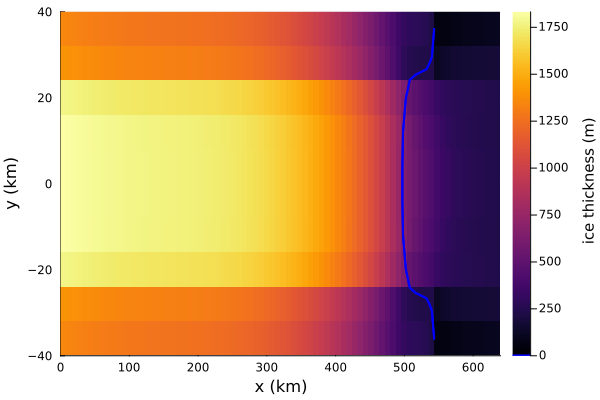

In [12]:
Plots.heatmap(simulation.model.grid.xxh[:,1]/1e3, simulation.model.grid.yyh[1,:]/1e3, simulation.model.fields.gh.h', 
                xlabel = "x (km)", 
                ylabel = "y (km)",
                colorbar_title = "\n ice thickness (m)", 
                right_margin = 4Plots.mm)

Plots.contour!(simulation.model.grid.xxh[:,1]/1e3, 
            simulation.model.grid.yyh[1,:]/1e3,
            simulation.model.fields.gh.grounded_fraction',
            fill = false,
            levels = [0.5,0.5],
            linecolor = :blue,
            linewidth = 2)
plot!(size = (600,400))

In [13]:
filename = joinpath(folder, "outfile.nc");

ds = NCDataset(filename, "r") do ds
    h_data = ds["h"][:, :, :]
    grfrac_data = ds["grfrac"][:, :, :]
    time_data = ds["TIME"][:]

    #compute the volume above floatation
    vaf = zeros(length(time_data)) 

    for i = 1:length(time_data)
        vaf[i] = volume_above_floatation(h_data[:, :, i], 
                                         simulation.model.fields.gh.b, 
                                         Ref(simulation.model.params), 
                                         simulation.model.grid)
    end

    return time_data, vaf
end

time, vaf = ds

([200.0, 400.0, 600.0, 800.0, 1000.0, 1200.0, 1400.0, 1600.0, 1800.0, 2000.0  …  8200.0, 8400.0, 8600.0, 8800.0, 9000.0, 9200.0, 9400.0, 9600.0, 9800.0, 10000.0], [2.92068208265242e12, 3.760686264233084e12, 4.763428111200807e12, 5.78921848285375e12, 6.931622032833783e12, 8.228932897748342e12, 9.70560169899041e12, 1.1374064420852217e13, 1.317161720757943e13, 1.4991565350452168e13  …  4.396710451551332e13, 4.404397370338862e13, 4.4105829368058586e13, 4.4155576187702875e13, 4.419555911629191e13, 4.422768148199222e13, 4.425347097188592e13, 4.427416458352645e13, 4.4290762885456945e13, 4.430407143687043e13])

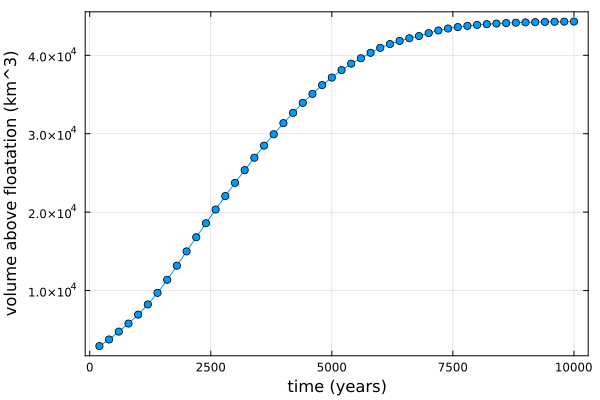

In [14]:
Plots.plot(time, vaf[:]/1e9,
marker = true, 
             label = :none,
             xlabel = "time (years)",
             ylabel = "volume above floatation (km^3)",
             framestyle = :box)

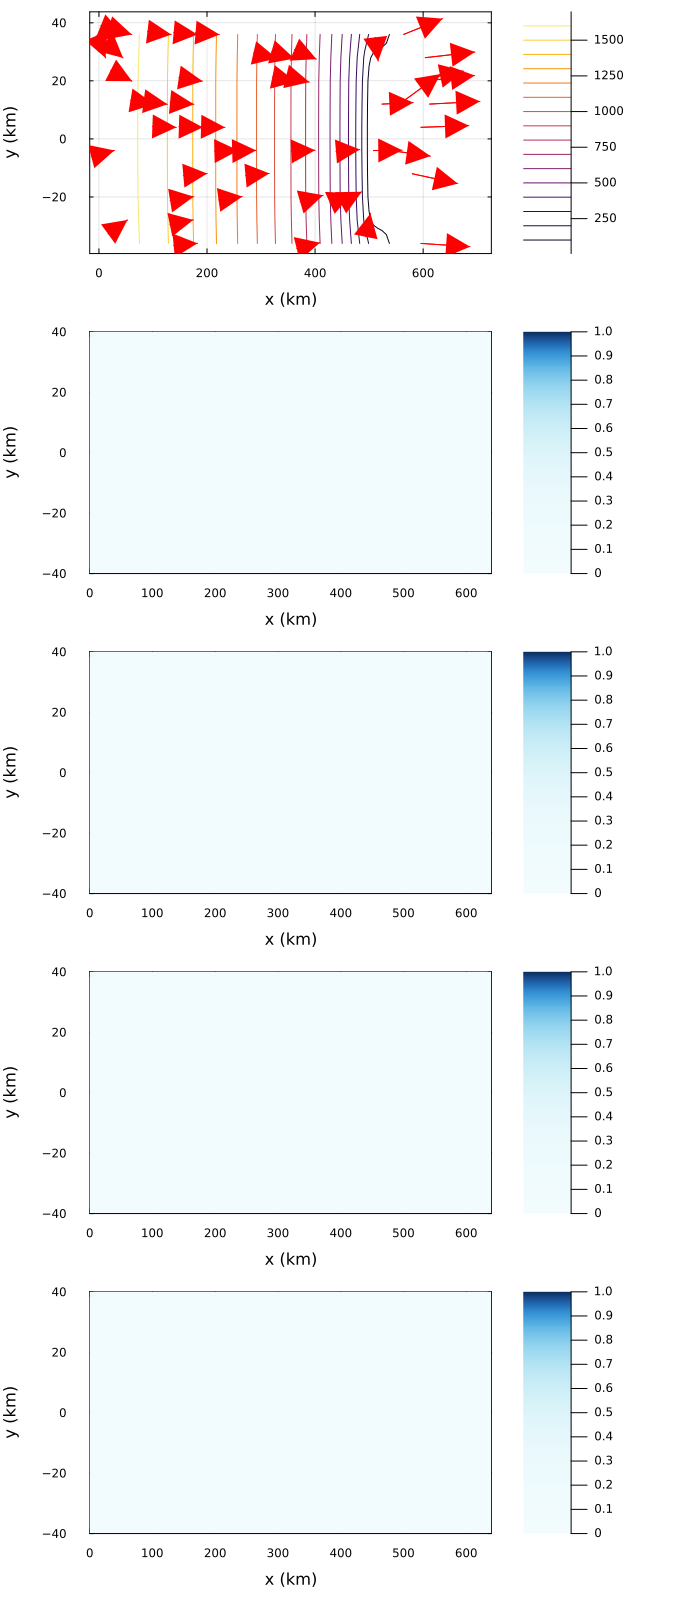

In [17]:
using Random
xx= simulation.model.grid.xxh/1000
yy = simulation.model.grid.yyh/1000
s = simulation.model.fields.gh.s
u = simulation.model.fields.gh.u
v = simulation.model.fields.gh.v
Φ = simulation.model.fields.g3d.Φ

arrow_length = 100/1000
n_arrows = 50
ss = randperm(length(xx))[1:n_arrows]
clim = (0,1.0)
cmap = colormap("Blues", logscale = true)
p1=heatmap(xx[:,1],yy[1,:],(Φ1[:,:,1])',clim = clim,xlabel="x (km)",ylabel="y (km)", colormap = cmap, framestyle = :box)
p2=heatmap(xx[:,1],yy[1,:],(Φ[:,:,2])',clim = clim,xlabel="x (km)",ylabel="y (km)", colormap = cmap, framestyle = :box)
p3=heatmap(xx[:,1],yy[1,:],(Φ[:,:,3])',clim = clim,xlabel="x (km)",ylabel="y (km)", colormap = cmap, framestyle = :box)
p4=heatmap(xx[:,1],yy[1,:],(Φ[:,:,4])',clim = clim,xlabel="x (km)",ylabel="y (km)", colormap = cmap, framestyle = :box)
p5=contour(xx[:,1],yy[1,:],s', levels = 0:100:2000,xlabel="x (km)",ylabel="y (km)", framestyle = :box)
p5 = quiver!(p5,xx[ss],yy[ss],quiver=(arrow_length*u[ss], arrow_length*v[ss]), color = :red, arrow = Plots.arrow(:closed, :head, 0.01, 0.01))
plot(p5,p4,p3,p2,p1;layout=(5,1),size=(700,1600),left_margin=10Plots.mm,right_margin=10Plots.mm)
